# Assignment 04: Topic modeling using supplied embeddings

**Overall purpose:** Answer the five crime-data questions on slide 11 using reproducible topic modeling and evidence-based report analysis. Your section must connect to the shared final report table and the main workstation.

## Shared rules: read before writing code

1. **Claim one assignment.** Add your name and reviewer below, then tell the group. These six notebooks are roles, not six tasks for each person.
2. **Use the shared files.** The original Parquet and shared/reports_base.parquet are read-only inputs. The base adds stable report_id values but does not clean or classify anything.
3. **Keep report_id.** Never recreate IDs after filtering, sorting or resetting an index. Join results using report_id with merge validation. URL is not a unique ID: some URLs repeat.
4. **Use one prepared version.** Member 1 must publish outputs/member_01/reports_prepared.parquet before final modeling. Preserve all source rows and mark exclusions. Everyone records that file's checksum in run_metadata.json. Prototype results on the base are exploratory and must be rerun on the agreed prepared file.
5. **Preserve alignment.** Build each text list and embedding matrix from the same filtered DataFrame in the same order. Never filter/sort text and embeddings separately.
6. **Separate analysis from evidence.** Write short code cells, show readable tables/plots, and explain actual outputs. Do not invent findings, silently fill missing districts, or treat a colored cluster plot as proof of meaningful crime types.
7. **Export to your own folder.** outputs/member_XX holds submissions; figures/member_XX holds readable figures. templates/member_XX contains empty examples and is never a finished submission.
8. **Finish with a peer review.** Everyone contributes their section, interpretation and sample reading. Member 6 coordinates validation; they do not write the entire group project.

**Your name:** Aya Abdine  
**Peer reviewer:** Pending - not assigned  
**Status:** Executed candidates - ready for peer review; acceptance pending  
**Prepared input version/checksum:** Local preparation for review; bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139


## Setup and input check

Keep this notebook inside team_notebooks, or beside the shared folder. Copy the project folder when sharing it; the notebook alone does not contain the dataset.

In [1]:
from pathlib import Path
from datetime import datetime
from importlib.metadata import version
from io import BytesIO, StringIO
from zoneinfo import ZoneInfo
import hashlib, json, os, platform, re, sys, tempfile, time

cache = Path(tempfile.gettempdir()) / 'bremen-member04-cache'
os.environ.update(HF_HOME=str(cache / 'huggingface'), HF_HUB_OFFLINE='1',
                  TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false',
                  NUMBA_NUM_THREADS='1', MPLCONFIGDIR=str(cache / 'matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

AUTHOR = 'Aya Abdine'
run_started = datetime.now(ZoneInfo('Europe/Berlin')).isoformat()
package_names = ['pandas', 'numpy', 'pyarrow', 'matplotlib', 'scipy', 'scikit-learn',
                 'umap-learn', 'hdbscan', 'bertopic', 'numba', 'sentence-transformers',
                 'transformers', 'torch', 'plotly', 'ipykernel', 'nbformat', 'nbclient']
package_versions = {name: version(name) for name in package_names}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print(f'Python {platform.python_version()}: {sys.executable}')
display(pd.Series(package_versions, name='Version').to_frame())

def show_table(table):
    display(HTML('<div style="max-height:420px;overflow:auto">' +
                 table.to_html(index=False, escape=True) + '</div>'))


Python 3.13.7: C:\Users\pc\AppData\Local\Temp\bremen-member04-env\Scripts\python.exe


,Version
pandas,2.3.2
numpy,2.3.3
pyarrow,26.0.0
matplotlib,3.10.6
scipy,1.16.2
scikit-learn,1.7.2
umap-learn,0.5.12
hdbscan,0.8.44
bertopic,0.17.4
numba,0.68.0


In [2]:
project_folder = Path.cwd()
if not (project_folder / "shared").exists():
    project_folder = project_folder.parent

assert (project_folder / "shared/source_manifest.json").exists(), "Open the notebook from the shared project folder."

In [3]:
output_folder = project_folder / "outputs/member_04"
figure_folder = project_folder / "figures/member_04"
output_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)

In [4]:
def sha256(path):
    with open(path, 'rb') as file:
        return hashlib.file_digest(file, 'sha256').hexdigest()

manifest = json.loads((project_folder / 'shared/source_manifest.json').read_text())
contracts = json.loads((project_folder / 'artifact_contracts.json').read_text())
schemas = contracts['roles']['member_04']['csv_schemas']
input_checksums = {}
for filename, key in [(manifest['raw_file'], 'raw_sha256'),
                      (manifest['base_file'], 'base_sha256')]:
    input_checksums[filename] = sha256(project_folder / filename)
    assert input_checksums[filename] == manifest[key], f'Input changed: {filename}'
assert manifest['base_sha256'] == contracts['base_sha256']
reports_base = pd.read_parquet(project_folder / manifest['base_file'])
assert len(reports_base) == contracts['base_rows'] == 5126
assert reports_base.report_id.notna().all() and reports_base.report_id.is_unique


In [5]:
prepared_path = project_folder / 'outputs/member_01/reports_prepared.parquet'
preparation_metadata = json.loads((prepared_path.parent / 'run_metadata.json').read_text())
preparation_handover = (prepared_path.parent / 'handover.md').read_text(encoding='utf-8')
prepared_checksum = sha256(prepared_path)
assert prepared_checksum == preparation_metadata['prepared_sha256']
assert prepared_checksum == 'bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139'
assert prepared_checksum in preparation_handover
input_checksums[prepared_path.relative_to(project_folder).as_posix()] = prepared_checksum
reports = pd.read_parquet(prepared_path)
print('Verified prepared SHA-256:', prepared_checksum)

# Verify ownership/version before replacing any existing Member 04 artifacts.
metadata_path = output_folder / 'run_metadata.json'
previous_metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else None
if previous_metadata:
    assert previous_metadata['member_id'] == 'member_04'
    assert previous_metadata['prepared_sha256'] == prepared_checksum
    for item in previous_metadata['output_inventory'] + previous_metadata['figure_inventory']:
        path = project_folder / item['path']
        assert path.resolve().is_relative_to(output_folder.resolve()) or path.resolve().is_relative_to(figure_folder.resolve())
        assert sha256(path) == item['sha256'], f'Existing artifact changed: {path.name}'


Verified prepared SHA-256: bf64238b7f929551cf20dadcdd314fa8bf17efe2cd7eab6174fd44dab1a1c139


### Packages

Select the tested interpreter printed above. The project `.venv` is still absent; this run uses the existing isolated Python 3.13.7 environment, while Member 1 recorded 3.12.2. Exact installed versions are saved in metadata. No global packages or shared requirements are changed.

For the eventual agreed project environment, install with `.\.venv\Scripts\python.exe -m pip install -r requirements.txt`, select that kernel and rerun. Offline settings prevent embedding-model downloads. Successful local execution does not imply team environment agreement or peer acceptance of the prepared data.


## Things to note throughout the project

- Count reports, not confirmed incidents or individual victims. One report can discuss several events or offenses. Treat the unit consistently.
- date_posted is a publication date. The first/last years and boundary months are partial; the source's collection coverage is not established by its date range alone.
- District labels include literal None and potentially different geographic levels. Unknown district reports still matter for citywide totals; district rankings need a consistent reviewed geography.
- Categories such as Theft, Traffic-related, Assault, Burglary, Fraud and Drug-related are candidate names, not predetermined model results. Include an Unknown/Unclear option and a documented non-crime/report-type category where needed.
- A topic is a group of similar reports, not automatically a legal crime category. Several topics can map to one category; mixed topics may need a per-report review.
- Use one primary category per report for the main count tables. If the group later adopts multiple labels, document that totals can exceed the report count and rebuild all comparisons consistently.
- The source includes descriptions of harmful events. Keep relevant evidence brief in outputs, avoid unnecessary identifying details, and use report IDs/source URLs for traceability.
- No API calls, paid services, extra scraping or AI-generated embeddings are needed to start. Optional AI-assisted elderly detection needs a separate agreed method and human verification.


## Purpose and dependencies

You implement the instructor's supplied-embedding pipeline and interpret its clusters as topics using BERTopic. This is a second topic-modeling approach, not just a colored plot.

Run two matched experiments: title_en with title_en_embeddings768 (model_id=bertopic_titles), and description_en with desc_en_embeddings768 (model_id=bertopic_descriptions). Reuse the existing embeddings; do not generate a different set or pair title text with description embeddings.

**Final input:** Member 1's frozen prepared data. **Handover receiver:** Member 6 for comparison/category selection. You can inspect embedding validity and prepare the code while waiting.

### 1. Verify the embedding arrays

Check lengths, finite numbers, missing arrays and numeric types. Each valid vector should contain 768 numbers. Build the text list, report IDs and stacked embedding matrix from the same filtered rows. Record invalid vectors with assignment_status=invalid_embedding; do not silently drop them.

In [6]:
required = {'report_id', 'title_en', 'description_en', 'title_en_embeddings768',
            'desc_en_embeddings768', 'include_in_analysis', 'exclusion_reason',
            'district_clean', 'date_posted'}
assert required <= set(reports.columns)
assert len(reports) == len(reports_base) and reports.report_id.is_unique
assert reports.report_id.map(lambda value: isinstance(value, str)).all()
assert set(reports.report_id) == set(reports_base.report_id)
included = reports.include_in_analysis
excluded_ids = {'BR001569', 'BR002114'}
assert pd.api.types.is_bool_dtype(included) and included.notna().all()
assert included.sum() == preparation_metadata['counts']['included'] == 5124
assert set(reports.loc[~included, 'report_id']) == excluded_ids
assert reports.loc[~included, 'exclusion_reason'].fillna('').str.strip().ne('').all()
assert reports.loc[included, 'exclusion_reason'].fillna('').str.strip().eq('').all()

# Align by permanent ID before checking unchanged source values.
source = reports[['report_id']].merge(reports_base, on='report_id', validate='one_to_one')
assert pd.api.types.is_datetime64_any_dtype(reports.date_posted)
assert reports.date_posted.notna().all()
assert reports.date_posted.reset_index(drop=True).eq(pd.to_datetime(source.date_posted)).all()
for column in ['title_en', 'description_en', 'district', 'url']:
    pd.testing.assert_series_equal(reports[column].reset_index(drop=True), source[column])
for column in ['title_en_embeddings768', 'desc_en_embeddings768']:
    assert all(np.array_equal(a, b) for a, b in zip(reports[column], source[column]))

def vector_issue(value):
    try:
        vector = np.asarray(value)
        if vector.shape != (768,): return 'wrong_shape_or_missing'
        if vector.dtype.kind not in 'iuf': return 'non_numeric'
        if np.isnan(vector).any(): return 'contains_nan'
        if not np.isfinite(vector).all(): return 'contains_infinity'
        return 'valid'
    except (TypeError, ValueError):
        return 'malformed'

pairs = {'bertopic_titles': ('title_en', 'title_en_embeddings768'),
         'bertopic_descriptions': ('description_en', 'desc_en_embeddings768')}
cohorts, checks, validation_rows = {}, {}, []
for model_id, (text_column, embedding_column) in pairs.items():
    missing = reports[text_column].fillna('').str.strip().eq('')
    issues = reports[embedding_column].map(vector_issue)
    valid = issues.eq('valid')
    frame = reports.loc[included & ~missing & valid].reset_index(drop=True)
    embeddings = np.stack(frame[embedding_column].to_numpy()).astype(np.float32)
    assert embeddings.shape == (len(frame), 768) and np.isfinite(embeddings).all()
    cohorts[model_id] = {'frame': frame, 'documents': frame[text_column].tolist(),
                         'ids': frame.report_id.tolist(), 'embeddings': embeddings}
    checks[model_id] = {'missing': missing, 'valid': valid}
    validation_rows.append({'model_id': model_id, 'total': len(reports),
        'included': int(included.sum()), 'excluded': int((~included).sum()),
        'valid_embeddings': int(valid.sum()), 'invalid_embeddings': int((~valid).sum()),
        'missing_text': int(missing.sum()), 'cohort_size': len(frame)})
assert cohorts['bertopic_titles']['ids'] == cohorts['bertopic_descriptions']['ids']
show_table(pd.DataFrame(validation_rows))
show_table(reports.loc[~included, ['report_id', 'exclusion_reason']])


model_id,total,included,excluded,valid_embeddings,invalid_embeddings,missing_text,cohort_size
bertopic_titles,5126,5124,2,5126,0,0,5124
bertopic_descriptions,5126,5124,2,5126,0,0,5124


report_id,exclusion_reason
BR001569,Duplicate of retained matching report BR001568
BR002114,Duplicate of retained matching report BR002113


All 5,126 IDs are unique and retained. Both experiments fit the same 5,124 eligible reports; BR001569 and BR002114 remain excluded duplicates. Neither text field is missing or blank, and every supplied vector is numeric, finite and 768-dimensional. Text, IDs and embeddings come from the same filtered rows.

Raw/base/prepared checksums and unchanged source values pass validation. This establishes technical suitability for clustering, not embedding quality or crime-category validity. Member 1's checksum matches, while peer acceptance of that prepared version remains pending.


### 2. Set up the topic pipeline

Use supplied embeddings → UMAP → HDBSCAN → BERTopic keyword representation. UMAP reduces dimensions, HDBSCAN groups similar points, and topic keywords help explain what the groups contain. BERTopic can take a precomputed embedding matrix through fit_transform(documents, embeddings). Use lightweight keyword representation; an LLM is not necessary.

In [7]:
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import adjusted_rand_score

# Only keyword representation is filtered; supplied embeddings/text stay aligned.
stop_words = sorted((set(ENGLISH_STOP_WORDS) - {'fire'}) |
                    {'bremen', 'police', 'officers', 'pm', 'www', 'https', 'com', 'polizei', 'ots'})
settings = {'baseline': {'n_neighbors': 15, 'min_cluster_size': 15, 'min_samples': 5},
            'balanced': {'n_neighbors': 15, 'min_cluster_size': 30, 'min_samples': 5},
            'broader': {'n_neighbors': 30, 'min_cluster_size': 50, 'min_samples': 10}}
selected_setting = 'balanced'

def build_model(config):
    return BERTopic(
        embedding_model=None,
        umap_model=UMAP(n_components=5, n_neighbors=config['n_neighbors'],
                        min_dist=0.0, metric='cosine', random_state=42, n_jobs=1),
        hdbscan_model=HDBSCAN(min_cluster_size=config['min_cluster_size'],
            min_samples=config['min_samples'], metric='euclidean',
            cluster_selection_method='eom', prediction_data=False, core_dist_n_jobs=1),
        vectorizer_model=CountVectorizer(stop_words=stop_words, ngram_range=(1, 2),
                                        min_df=1, token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b'),
        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
        top_n_words=10, calculate_probabilities=False, verbose=False)

show_table(pd.DataFrame(settings).T.rename_axis('candidate').reset_index())


candidate,n_neighbors,min_cluster_size,min_samples
baseline,15,15,5
balanced,15,30,5
broader,30,50,10


Embeddings describe text meaning as numeric vectors, so reports can be close even when they use different words. We reuse the supplied vectors. Titles and descriptions are modeled separately to compare brief headlines with fuller context on the same reports.

UMAP reduces the 768 dimensions to five while preserving nearby relationships approximately. HDBSCAN finds dense groups and leaves uncertain reports as noise (-1). BERTopic uses the grouped texts to identify characteristic words through class-based TF-IDF. Those words describe topics; they do not establish legal crime categories.

Three unchanged settings test finer versus broader grouping. Seed 42 and single-thread settings support repeatability; software versions still matter. The balanced setting is a working candidate, not an optimized winner. See [BERTopic's supplied-embedding guidance](https://maartengr.github.io/BERTopic/getting_started/embeddings/embeddings.html) and [UMAP clustering cautions](https://umap-learn.readthedocs.io/en/latest/clustering.html).


### 3. Cluster and create a separate 2D view

Start with a small reduced space such as 5 dimensions for HDBSCAN and a separate 2D UMAP view for plotting. Compare a 2D clustering run if helpful for the instructor example. Explain that a 2D projection can lose structure. Use a fixed seed and a few documented n_neighbors/min_cluster_size candidates; do not select the model only because its plot looks tidy.

In [8]:
candidates, sensitivity_rows = {}, []
for model_id, cohort in cohorts.items():
    candidates[model_id] = {}
    for name, config in settings.items():
        start = time.perf_counter()
        model = build_model(config)
        labels, _ = model.fit_transform(cohort['documents'], cohort['embeddings'])
        elapsed = time.perf_counter() - start
        labels = np.asarray(labels, dtype=int)
        candidates[model_id][name] = {'model': model, 'labels': labels, 'seconds': elapsed}
        sizes = pd.Series(labels[labels >= 0]).value_counts()
        baseline = candidates[model_id]['baseline']['labels']
        common = (labels >= 0) & (baseline >= 0)
        sensitivity_rows.append({
            'model_id': model_id, 'candidate': name, 'modeling_cohort': len(labels),
            'n_topics': len(sizes), 'assigned_reports': int((labels >= 0).sum()),
            'unassigned_reports': int((labels == -1).sum()), 'noise_rate': float((labels == -1).mean()),
            'smallest_topic': int(sizes.min()) if len(sizes) else 0,
            'median_topic': float(sizes.median()) if len(sizes) else 0,
            'largest_topic_share': float(sizes.max() / len(labels)) if len(sizes) else 0,
            'elapsed_seconds': elapsed, 'ARI_vs_baseline_including_noise': adjusted_rand_score(baseline, labels),
            'common_assigned_share': float(common.mean()),
            'ARI_common_assigned_vs_baseline': adjusted_rand_score(baseline[common], labels[common]) if common.sum() > 1 else None})
        print(f'{model_id} / {name}: {len(sizes)} topics, {elapsed:.2f} s')
sensitivity = pd.DataFrame(sensitivity_rows)
show_table(sensitivity[['model_id', 'candidate', 'n_topics', 'noise_rate',
                        'median_topic', 'largest_topic_share', 'elapsed_seconds']].round(4))
show_table(sensitivity[['model_id', 'candidate', 'ARI_vs_baseline_including_noise',
                        'common_assigned_share', 'ARI_common_assigned_vs_baseline']].round(4))


bertopic_titles / baseline: 130 topics, 82.99 s


bertopic_titles / balanced: 59 topics, 21.19 s


bertopic_titles / broader: 26 topics, 26.68 s


bertopic_descriptions / baseline: 88 topics, 26.62 s


bertopic_descriptions / balanced: 36 topics, 25.42 s


bertopic_descriptions / broader: 27 topics, 33.56 s


model_id,candidate,n_topics,noise_rate,median_topic,largest_topic_share,elapsed_seconds
bertopic_titles,baseline,130,0.1598,29.0,0.0185,82.9856
bertopic_titles,balanced,59,0.1056,57.0,0.0693,21.1919
bertopic_titles,broader,26,0.0995,117.5,0.0984,26.6764
bertopic_descriptions,baseline,88,0.1717,33.5,0.0806,26.6205
bertopic_descriptions,balanced,36,0.0654,74.5,0.1099,25.4213
bertopic_descriptions,broader,27,0.0900,130.0,0.1655,33.5623


model_id,candidate,ARI_vs_baseline_including_noise,common_assigned_share,ARI_common_assigned_vs_baseline
bertopic_titles,baseline,1.0000,0.8402,1.0000
bertopic_titles,balanced,0.2719,0.7801,0.5820
bertopic_titles,broader,0.1482,0.7660,0.2760
bertopic_descriptions,baseline,1.0000,0.8283,1.0000
bertopic_descriptions,balanced,0.4125,0.8084,0.6882
bertopic_descriptions,broader,0.3312,0.7824,0.5600


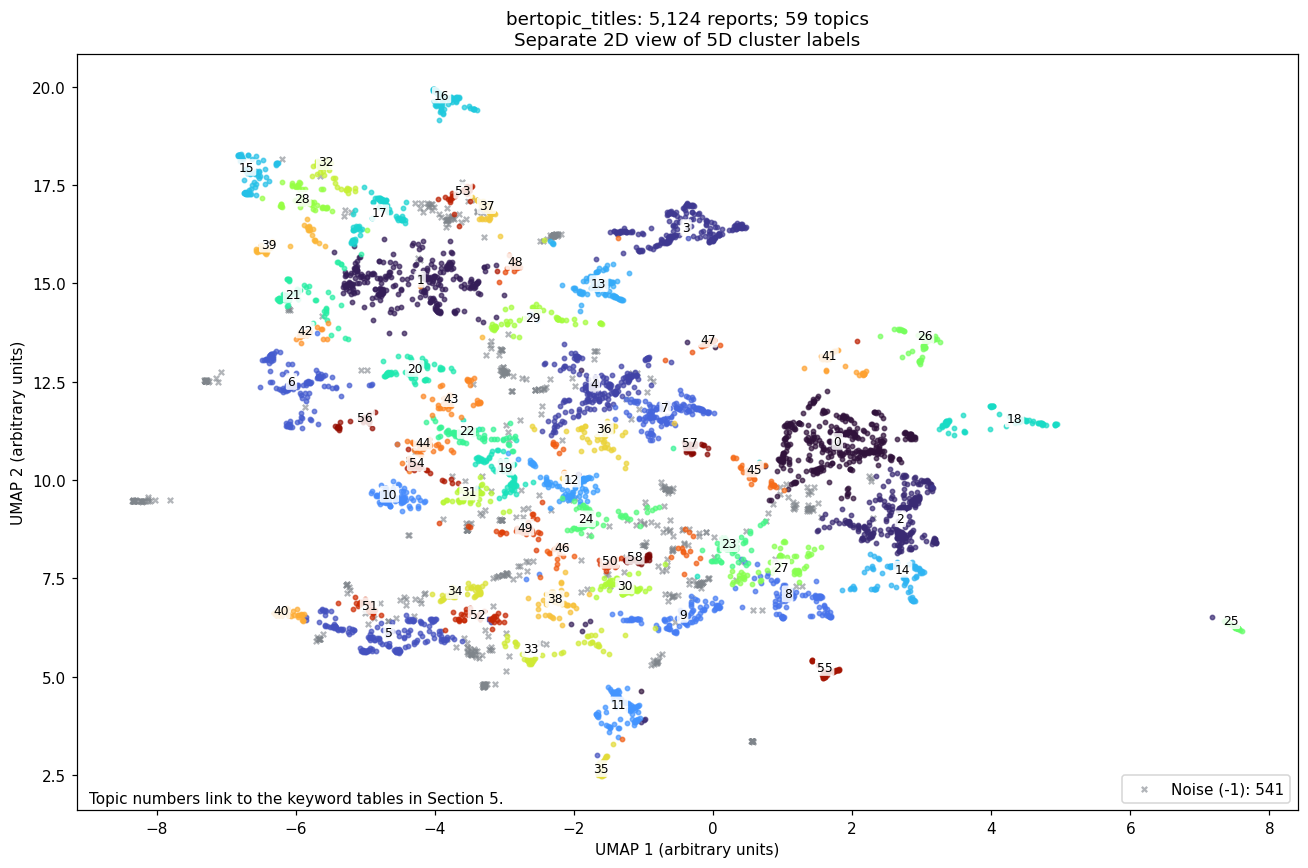

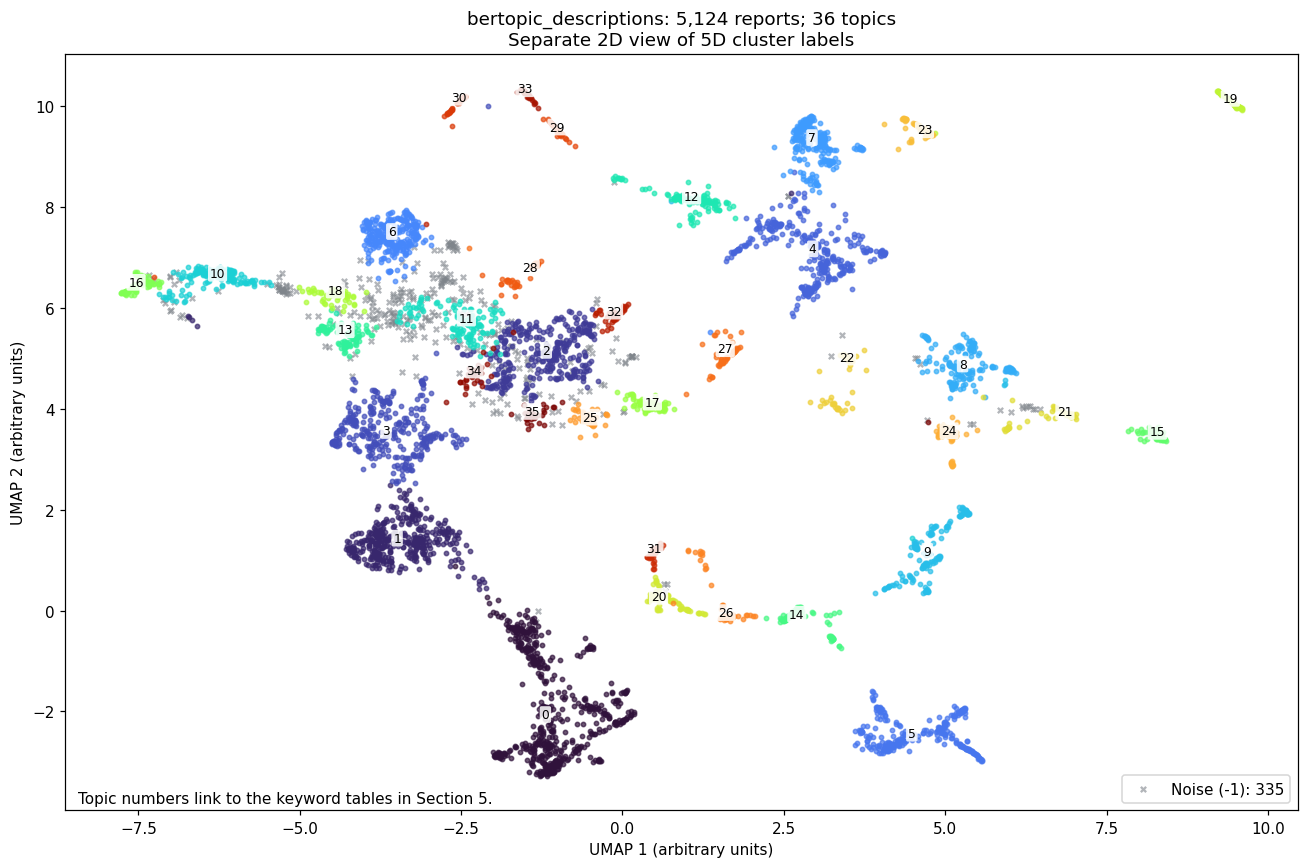

In [9]:
figure_bytes = {}  # Publish figures only after the full run passes export validation.
def keep_figure(figure, filename):
    buffer = BytesIO()
    figure.savefig(buffer, format='png', dpi=200, bbox_inches='tight')
    figure_bytes[filename] = buffer.getvalue()
    display(figure)
    plt.close(figure)

for model_id, cohort in cohorts.items():
    projection = UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                      metric='cosine', random_state=42, n_jobs=1).fit_transform(cohort['embeddings'])
    labels = candidates[model_id][selected_setting]['labels']
    topics = sorted(set(labels) - {-1})
    colors = plt.get_cmap('turbo', max(1, len(topics)))
    figure, axis = plt.subplots(figsize=(12, 8))
    noise = labels == -1
    axis.scatter(*projection[noise].T, s=12, c='#7f858b', alpha=0.6,
                 marker='x', label=f'Noise (-1): {noise.sum():,}')
    for color, topic in enumerate(topics):
        points = projection[labels == topic]
        axis.scatter(*points.T, s=8, color=colors(color), alpha=0.7)
        axis.text(*np.median(points, axis=0), str(topic), fontsize=8, ha='center',
                  bbox={'boxstyle': 'round,pad=.15', 'facecolor': 'white', 'alpha': .85, 'edgecolor': 'none'})
    axis.set(title=f'{model_id}: {len(labels):,} reports; {len(topics)} topics\nSeparate 2D view of 5D cluster labels',
             xlabel='UMAP 1 (arbitrary units)', ylabel='UMAP 2 (arbitrary units)')
    axis.legend(loc='lower right')
    axis.text(.01, .01, 'Topic numbers link to the keyword tables in Section 5.', transform=axis.transAxes)
    figure.tight_layout()
    keep_figure(figure, f'{model_id}_umap2d.png')


The selected runs identify 59 title topics and 36 description topics. The separate 2D views contain compact groups, overlapping regions and gray noise crosses (541 titles; 335 descriptions). Topic numbers link to Section 5. A topic can appear in several areas of this independent projection.

Topic counts vary across settings: 26-130 for titles and 27-88 for descriptions. UMAP can distort density and continuity, so visible separation does not prove correct categories. Cluster membership comes from the five-dimensional pipeline, never the plotting coordinates.


### 4. Fit both matched experiments

Use the same prepared input/evaluation cohort and sensible settings for titles and descriptions. Do not overwrite the two topic lists or export them under the same model ID. Keep HDBSCAN label -1 as unassigned noise unless individual reports are later reviewed. A low noise share alone does not prove good categories.

In [10]:
# Reuse the selected fitted objects: no duplicate final fit.
runs = {model_id: results[selected_setting] for model_id, results in candidates.items()}
summary_columns = ['model_id', 'modeling_cohort', 'n_topics', 'assigned_reports',
                   'unassigned_reports', 'noise_rate', 'elapsed_seconds',
                   'median_topic', 'largest_topic_share']
model_summary = sensitivity.loc[sensitivity.candidate.eq(selected_setting), summary_columns].copy()
model_summary = model_summary.rename(columns={'median_topic': 'median_assigned_topic_size'})
show_table(model_summary.round(4))

# Largest four topics per setting provide comparable development evidence.
for model_id, results in candidates.items():
    evidence = []
    for name, result in results.items():
        for topic in result['model'].get_topic_info().query('Topic >= 0').head(4).itertuples():
            positions = np.flatnonzero(result['labels'] == topic.Topic)
            position = np.random.default_rng(42 + int(topic.Topic)).choice(positions)
            evidence.append({'candidate': name, 'topic_id': topic.Topic, 'n_reports': topic.Count,
                'keywords': '; '.join(word for word, _ in result['model'].get_topic(topic.Topic)[:7]),
                'random_report_id': cohorts[model_id]['ids'][position],
                'random_title': cohorts[model_id]['frame'].iloc[position].title_en[:140]})
    print(model_id)
    show_table(pd.DataFrame(evidence))


model_id,modeling_cohort,n_topics,assigned_reports,unassigned_reports,noise_rate,elapsed_seconds,median_assigned_topic_size,largest_topic_share
bertopic_titles,5124,59,4583,541,0.1056,21.1919,57.0,0.0693
bertopic_descriptions,5124,36,4789,335,0.0654,25.4213,74.5,0.1099


bertopic_titles


candidate,topic_id,n_reports,keywords,random_report_id,random_title
baseline,0,95,injured knife; stab; stab wounds; wounds; man injured; knife injured; injured stab,BR000274,Injured with knife - Youths clash in neighborhood
baseline,1,80,gas station; station robbed; station robbery; station gas; robbery gas; gas; robs gas,BR003092,Witness appeal after gas station robbery
baseline,2,75,apprehended robbery; robbers apprehended; robber caught; apprehend robbers; robbery arrest; robber apprehended; robbery robber,BR002960,Suspected perpetrator apprehended after robbery
baseline,3,75,bicycle thieves; thieves caught; bicycle; thieves; copper; metal; bicycle thief,BR004812,Police arrest gangs of thieves
balanced,0,355,neustadt; grpelingen; huchting; vegesack; car fires; schwachhausen; hemelingen,BR000275,Police operation in the Neustadt
balanced,1,297,thief; street robber; thieves; robbers; car thief; street robbers; robber,BR002641,Police apprehends alleged metal thief
balanced,2,264,eve; bremens; years; new years; years eve; breminale; east,BR002856,Further Investigative Successes for the Bremen Police
balanced,3,210,fake; warns; workers; fake water; shock; water; trick,BR004617,Police warns of fake carpet dealers
broader,0,504,traffic accident; accident; traffic; cyclist; injured traffic; seriously injured; seriously,BR000445,Traffic accident in the old town
broader,1,451,neustadt; grpelingen; bomb; huchting; detonated; mitte; successfully,BR002170,Police operation in Burg-Grambke ended


bertopic_descriptions


candidate,topic_id,n_reports,keywords,random_report_id,random_title
baseline,0,413,burglar; burglary; tools; apprehended; stolen; window; theft,BR000411,Police arrests burglar
baseline,1,260,till; employee; black; threatened employee; gas station; wore; demanded,BR002999,Man robs gas station
baseline,2,147,water; doorbell; rang doorbell; rang; apartment; senior; utility,BR003486,So expensive? Police nabs con artist
baseline,3,144,license; endangering road; endangering; drivers license; influence; driving; driving license,BR004838,Traffic accident under the influence of drugs
balanced,0,563,accident; driver; traffic; collided; driving; car; injuries,BR000485,Escape ends at the house wall
balanced,1,413,burglar; apprehended; burglary; stolen; window; tools; arrested,BR002436,Police catch burglar
balanced,2,330,altercation; stab; homicide; wounds; knife; injured; argument,BR003509,Teenager with stab wounds to hospital
balanced,3,320,robbery; arrested; young; apprehended; phone; wallet; arrest,BR004423,Owner gets stolen mobile phone back
broader,0,848,altercation; head; man; hospital; injured; attacked; men,BR000360,Shots in Neustadt - Police and public prosecutor's office investigate
broader,1,415,burglar; apprehended; stolen; burglary; window; tools; arrested,BR002402,Burglar caught red-handed


Titles assign 4,583 reports with 541 noise cases (10.56%); descriptions assign 4,789 with 335 noise cases (6.54%). Both denominators are 5,124 eligible reports. Description topics are larger: median 74.5 versus 57 reports, and largest-topic shares 10.99% versus 6.93%. Fit times appear in the table and exclude plotting/export.

The balanced setting retains detail without the baseline's 130 title/88 description topics. The broader title run merges graffiti/fire vocabulary; the broader description run combines 848 reports in a broad violence group, whereas balanced retains separate recognizable themes. Balanced still has mixed place/press-release groups, so it is a defensible working compromise rather than a validated optimum. Selection considers examples and topic sizes alongside noise.

Partition agreement with baseline changes substantially: ARI including noise is 0.272 (titles) and 0.412 (descriptions); on reports assigned by both settings it is 0.582 and 0.688. These measure parameter sensitivity, not category accuracy. The broader run changes several parameters together. Different seeds, resampling and independent human validation remain untested.


### 5. Interpret clusters as topics

Show top keywords, topic sizes and representative/random report examples for both models. Propose meaningful category names and identify mixed groups or boilerplate/place-name clusters. Keep text largely intact for alignment with supplied embeddings; adjust keyword representation separately when generic terms obscure meaning.

In [11]:
category_terms = {'Theft': {'theft', 'bicycle', 'shoplifting', 'stolen', 'pickpocket', 'steal', 'thieves'},
 'Burglary': {'breakin', 'break ins', 'burglaries', 'burglary', 'burglar', 'break in', 'burglars'},
 'Robbery': {'robbery', 'robber', 'robbers', 'robs', 'robberies', 'robbed'},
 'Assault / violence': {'altercation', 'assault', 'attack', 'attacked', 'brawl', 'fight', 'gunshot',
                        'homicide', 'knife', 'stab', 'stabbed', 'stabbing'},
 'Traffic-related': {'accident', 'accidents', 'collision', 'driver', 'driving', 'traffic',
                     'vehicle'},
 'Fraud / deception': {'fraud', 'fraudster', 'fraudsters', 'impersonation', 'scam', 'scammers',
                       'trick'},
 'Drug-related': {'narcotics', 'drug', 'drugs', 'cocaine', 'marijuana', 'cannabis'},
 'Vandalism / property damage': {'damaged', 'damage', 'graffiti', 'vandalism'},
 'Fire / explosion reports': {'fire', 'disposal', 'explosion', 'arson', 'bomb', 'fires'},
 'Public events / police information': {'assembly', 'demonstration', 'demonstrations', 'event',
                                        'events', 'football', 'match', 'protest'},
 'Missing-person / appeal reports': {'missing', 'search', 'appeal', 'witnesses'}}

place_words = {re.sub('[^a-z ]', '', str(v).lower()).strip() for v in reports.district_clean.unique()} - {'unknown'}

def propose_category(words, topic):
    if topic == -1:
        return ('Unknown/Unclear', 'Noise (-1); no coherent topic asserted; report-level review required.')
    if sum((w in place_words for w in words[:10])) >= 3:
        return ('Mixed / requires review', 'Place-heavy keywords; a crime cue does not establish topic-wide category. Review representative AND random examples.')
    if 'psychiatric' in ' '.join(words):
        return ('Unknown/Unclear', 'Mental-health/police intervention cues; do not assume a confirmed crime from a weapon keyword; review context.')
    scores = {cat: sum((any((term == w or term in w.split() for term in terms)) for w in words[:10])) for cat, terms in category_terms.items()}
    positive = sorted([(score, cat) for cat, score in scores.items() if score > 0], reverse=True)
    if not positive:
        return ('Unknown/Unclear', 'No strong keyword-rule match; possible reporting style/place topic; review required.')
    if len(positive) > 1 and positive[1][0] >= positive[0][0] * 0.6:
        return ('Mixed / requires review', 'Competing keyword cues: ' + '; '.join((cat for score, cat in positive[:3])) + '. Provisional; inspect context.')
    return (positive[0][1], 'Keyword-rule proposal only; not independently validated. Other cues: ' + ('; '.join((cat for score, cat in positive[1:3])) or 'none detected') + '.')

def brief(text, limit=170):
    text = re.sub('https?://\\S+|\\b[\\w.+-]+@[\\w.-]+\\b', '[link/contact removed]', str(text))
    text = re.sub('\\b\\d[\\d ()/+-]{5,}\\d\\b', '[number removed]', text)
    return re.sub('\\s+', ' ', text).strip()[:limit]


In [12]:
topic_tables, sample_tables, evidence_tables = {}, {}, {}
for model_id, result in runs.items():
    frame = cohorts[model_id]['frame']
    documents = cohorts[model_id]['documents']
    model, labels = result['model'], result['labels']
    topics, samples, evidence = [], [], []
    for topic in sorted(set(labels)):
        positions = np.flatnonzero(labels == topic)
        words = [word for word, _ in (model.get_topic(int(topic)) or []) if word]
        category, notes = propose_category(words, int(topic))
        topics.append({'model_id': model_id, 'topic_id': int(topic), 'keywords': '; '.join(words),
                       'n_reports': len(positions), 'proposed_category': category, 'notes': notes})
        representative = []
        if topic >= 0:
            for text in model.get_representative_docs(int(topic)) or []:
                position = next((i for i in positions if documents[i] == text and i not in representative), None)
                if position is not None: representative.append(position)
        representative = representative[:3]
        remaining = np.array([i for i in positions if i not in representative], dtype=int)
        random = np.random.default_rng(42 + int(topic) + 1).choice(
            remaining, size=min(2 if topic >= 0 else 3, len(remaining)), replace=False)
        selected = [(i, 'representative_c_tf_idf') for i in representative]
        selected += [(int(i), 'random_seed_42_plus_topic_plus_1') for i in random]
        for position, reason in selected:
            report_id = frame.iloc[position].report_id
            samples.append({'model_id': model_id, 'topic_id': int(topic),
                            'report_id': report_id, 'selection_reason': reason})
            evidence.append({'topic_id': int(topic), 'report_id': report_id,
                'selection': 'Representative' if reason == 'representative_c_tf_idf' else 'Random',
                'title': brief(frame.iloc[position].title_en, 120),
                'text_excerpt': brief(documents[position])})
    topic_tables[model_id] = pd.DataFrame(topics)
    sample_tables[model_id] = pd.DataFrame(samples)
    evidence_tables[model_id] = pd.DataFrame(evidence)


bertopic_titles


topic_id,n_reports,keywords,proposed_category
-1,541,kicks head; kicks; head; suspicious; closure,Unknown/Unclear
0,355,neustadt; grpelingen; huchting; vegesack; car fires,Mixed / requires review
1,297,thief; street robber; thieves; robbers; car thief,Mixed / requires review
2,264,eve; bremens; years; new years; years eve,Unknown/Unclear
3,210,fake; warns; workers; fake water; shock,Fraud / deception
4,191,graffiti; paint; sprayer; vandalism; party office,Vandalism / property damage
5,168,injured traffic; dies; dies traffic; traffic accident; hit,Traffic-related
6,135,woman robbed; taxi driver; driver robbed; handbag; taxi,Robbery
7,134,fire; arson; arson attack; responsibility; burned,Fire / explosion reports
8,105,assembly; demo; demonstration; block; saturday,Public events / police information


topic_id,report_id,selection,text_excerpt
-1,BR003571,Random,Female cyclist seriously injured in traffic accident
-1,BR000423,Random,Arson in the Überseestadt - Confession letter surfaced
-1,BR004020,Random,Severe clashes
0,BR003967,Representative,Vehicle fire in Neustadt
0,BR002732,Random,Car fire in Schwachhausen
0,BR001827,Random,Witness search following a sexual offense in Gröpelingen
1,BR000264,Representative,Bicycle thieves caught
1,BR003306,Random,Two catalyst thieves caught
1,BR000851,Random,Blue Pinot Noir wine thief apprehended in the old town
2,BR003958,Representative,Encrochat Investigation: Public Prosecutor's Office Bremen and Bremen Police are investigating on suspicion of organized drug trafficking - 13 properties in Bremen search


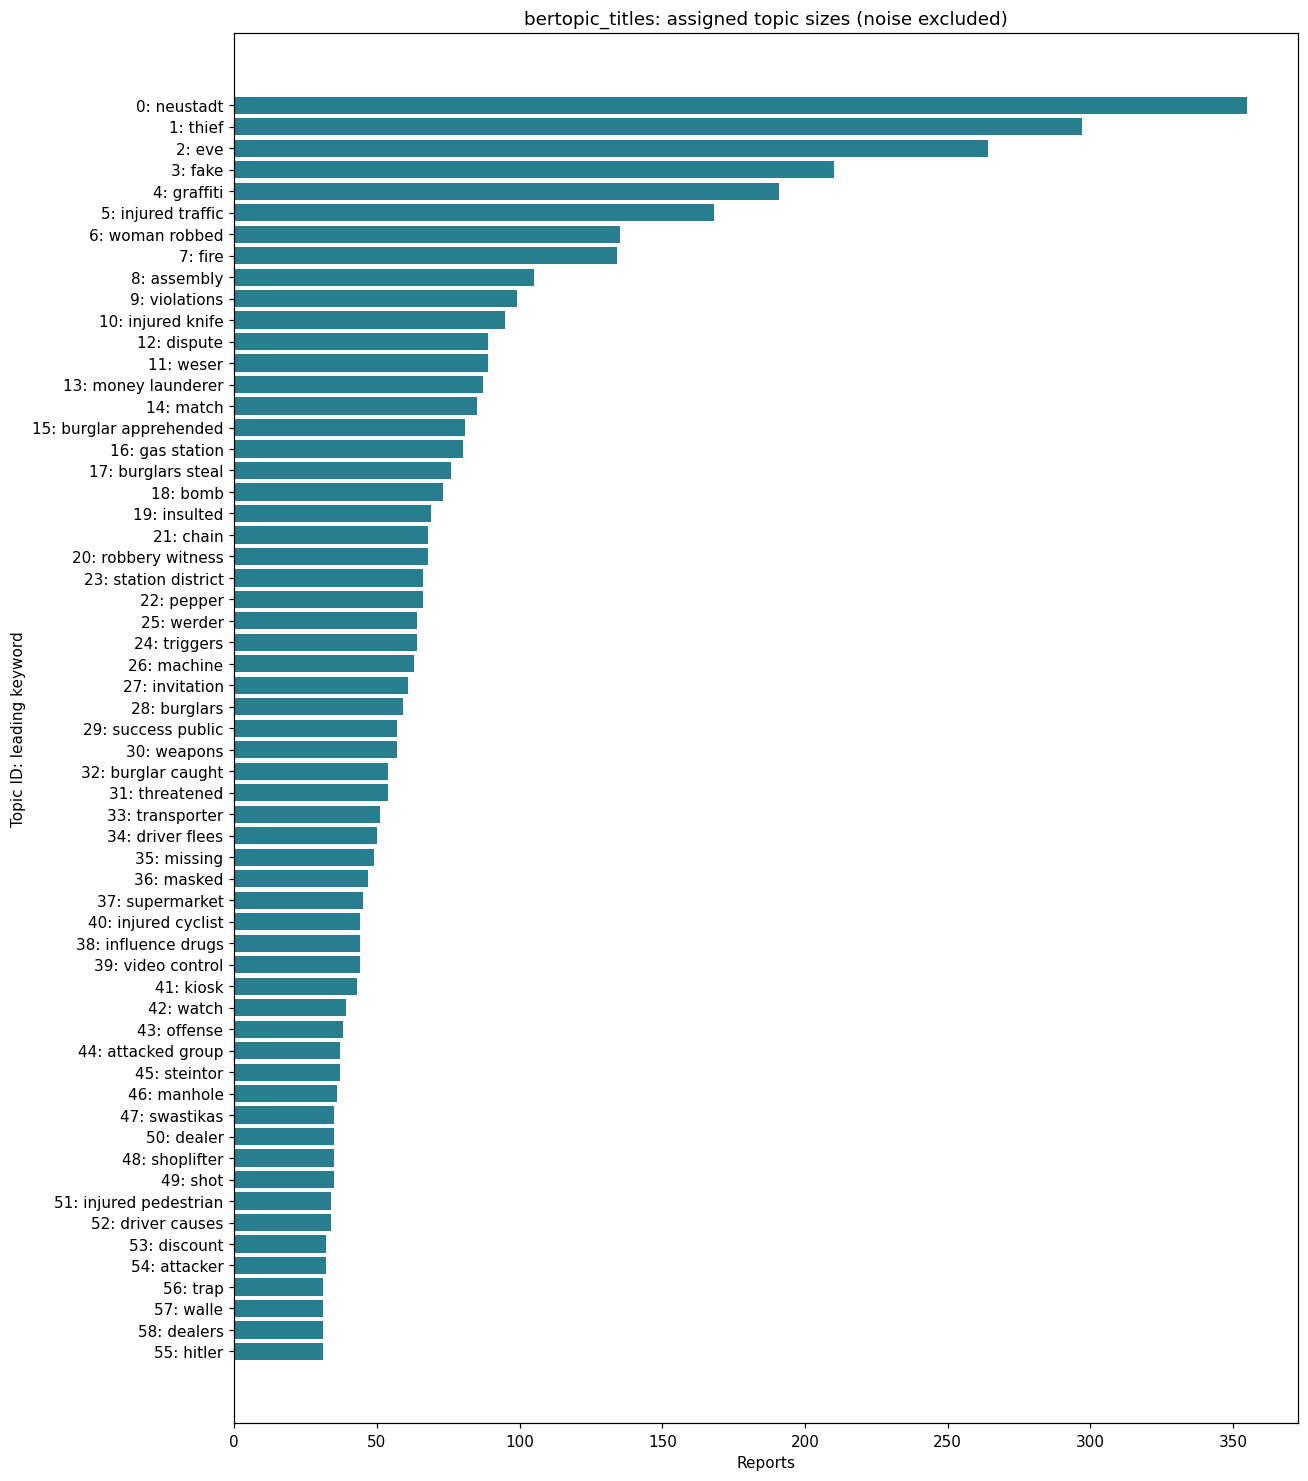

bertopic_descriptions


topic_id,n_reports,keywords,proposed_category
-1,335,dark; unknown; fled; pepper spray; pepper,Unknown/Unclear
0,563,accident; driver; traffic; collided; driving,Traffic-related
1,413,burglar; apprehended; burglary; stolen; window,Mixed / requires review
2,330,altercation; stab; homicide; wounds; knife,Assault / violence
3,320,robbery; arrested; young; apprehended; phone,Robbery
4,319,paint; graffiti; defaced; unknown persons; facade,Vandalism / property damage
5,279,drug; cannabis; seized; cocaine; narcotics,Drug-related
6,260,black; employee; till; wore; entered,Robbery
7,227,fire; burned; flames; arson; extinguished,Fire / explosion reports
8,158,assembly; participants; rally; demonstration; procession,Public events / police information


topic_id,report_id,selection,title,text_excerpt
-1,BR003573,Random,Elderly woman robbed in apartment - Call for witnesses,Two previously unknown perpetrators robbed a 76-year-old woman from Bremen in her apartment in Sebaldsbrück on Thursday evening. The robbers made off with cash and fled.
-1,BR000462,Random,Gold chain stolen,"Two unknown men robbed a 34-year-old man of a gold chain in Neustadt on Wednesday morning. Police are looking for witnesses.At around 11:15 AM, the 34-year-old was in Bru"
-1,BR003973,Random,22-year-old ambushed during sales transaction,"On Wednesday, an unknown perpetrator assaulted a 22-year-old in Bremen's Neustadt district. The police are looking for witnesses and providing prevention tips. The 22-yea"
0,BR003469,Representative,Nine injured in accident on the A27,"On Tuesday afternoon, two vehicles collided on the A 27 motorway in the direction of Hanover. Nine people were injured, including five children. A kilometer-long traffic"
0,BR003361,Random,Woman dies after accident,"On Tuesday morning, a traffic accident occurred in Vegesack. An 82-year-old woman succumbed to her injuries. The 82-year-old Vegesack resident was crossing the Aumunder H"
0,BR002681,Random,Traffic accident involving patrol car,A patrol car collided with another car on an emergency call in the Östliche Vorstadt on Sunday night. Five people were slightly injured in the process. According to curre
1,BR004812,Representative,Police arrest gangs of thieves,"On Tuesday and Wednesday, gangs of thieves were operating in Bremen-Vahr and Bremen-Osterholz. Thanks to vigilant witnesses in both cases, emergency services were able to"
1,BR003219,Random,Burglar apprehended,"In the Bremen Old Town, a group of people caught a burglar in their apartment on early Wednesday evening. They detained the 54-year-old and locked him in until the police"
1,BR000551,Random,Burglar apprehended,Bremen police officers apprehended a 32-year-old man in Neustadt in the night from Saturday to Sunday. He is suspected of having broken into a snack bar shortly before. A
2,BR003466,Representative,Conflicts involving knives,"On Wednesday, altercations occurred in Walle and Vegesack, in which knives were also used. A 60-year-old Bremen resident sustained stab and cut wounds. Emergency services"


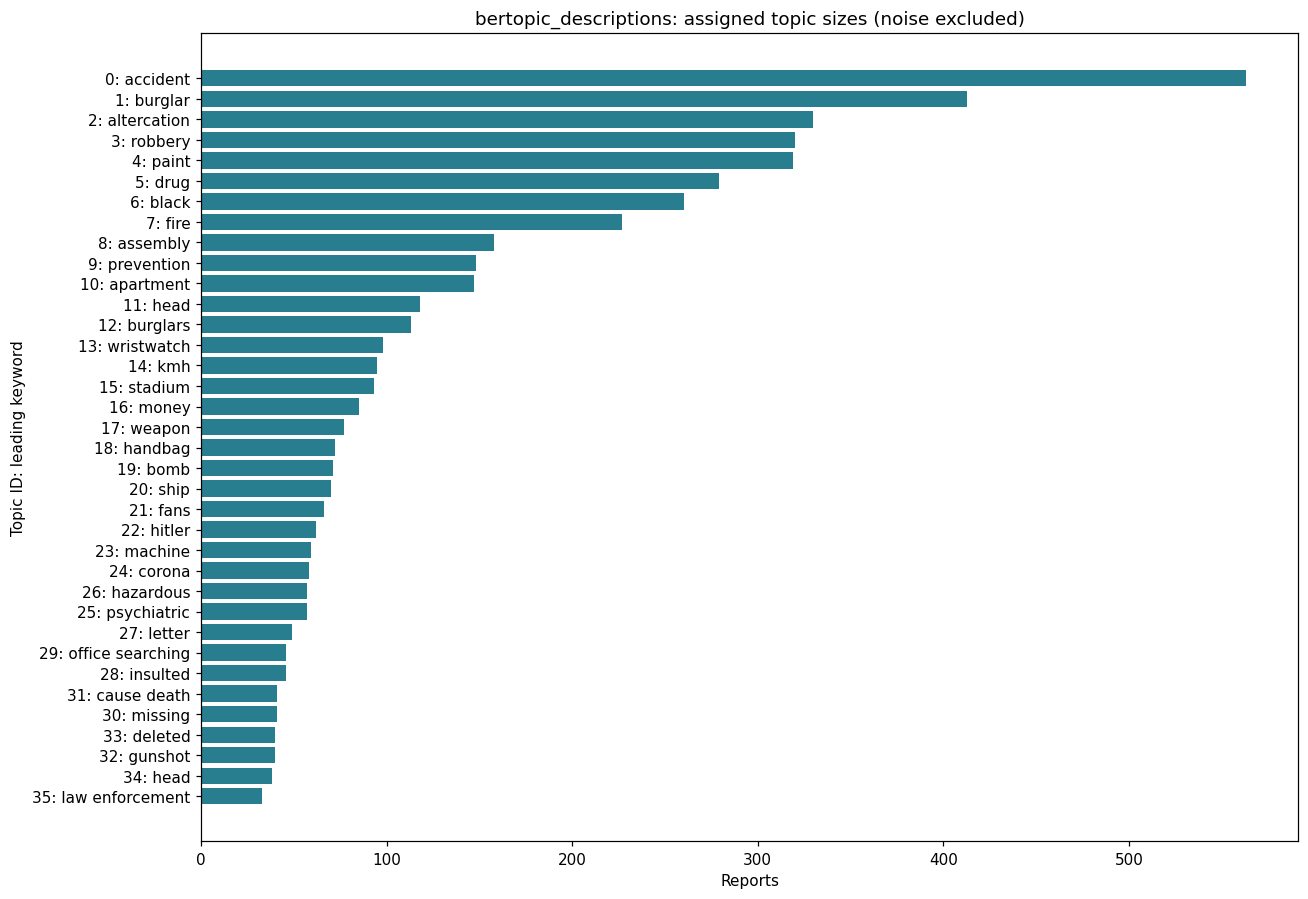

In [13]:
for model_id, topics in topic_tables.items():
    print(model_id)
    summary = topics[['topic_id', 'n_reports', 'keywords', 'proposed_category']].copy()
    summary['keywords'] = summary.keywords.str.split('; ').str[:5].str.join('; ')
    show_table(summary)
    # Show one representative and all random examples; the full sample CSV retains every selected ID.
    evidence = evidence_tables[model_id]
    preview = evidence.loc[evidence.selection.eq('Random') | ~evidence.duplicated(['topic_id', 'selection'])]
    columns = ['topic_id', 'report_id', 'selection', 'text_excerpt']
    if model_id == 'bertopic_descriptions': columns.insert(3, 'title')
    show_table(preview[columns])
    sizes = topics.query('topic_id >= 0').sort_values('n_reports')
    figure, axis = plt.subplots(figsize=(12, max(5, len(sizes) * .23)))
    names = [f"{row.topic_id}: {row.keywords.split(';')[0]}" for row in sizes.itertuples()]
    axis.barh(names, sizes.n_reports, color='#287d8e')
    axis.set(title=f'{model_id}: assigned topic sizes (noise excluded)',
             xlabel='Reports', ylabel='Topic ID: leading keyword')
    figure.tight_layout()
    keep_figure(figure, f'{model_id}_topic_sizes.png')


Titles show recognizable fraud warnings (topic 3: 210 reports), graffiti/property damage (4: 191), traffic accidents (5: 168) and football announcements (25: 64). Topic 1 mixes theft/robbery language. Place-heavy topic 0 (355) includes BR001827, a different offense from its car-fire representatives. Topic 2 (264) mixes press-release, event and fraud language; bomb-disposal topic 18 (73) contains the contrasting random example BR002522. These examples explain why representative texts alone can overstate coherence.

Descriptions offer clearer context in the inspected examples: traffic (0: 563), burglary/theft (1: 413), drugs (5: 279), assemblies (8: 158) and bomb disposal (19: 71). Media/prevention topic 9 (148) and football/traffic-planning topic 15 (93) are not conventional crime categories. Topic 10 (147) has apartment/water/doorbell keywords, while its samples concern bogus utility workers; a keyword rule alone misses that context.

Mixed examples remain: graffiti topic 4 includes motorway report BR000504, and topic 27 combines suspicious mail with a drone report. Psychiatric/weapon intervention cues do not establish a confirmed crime. Descriptions appear easier to interpret qualitatively, but no validated ranking or accuracy is claimed. All proposals await human review. Every topic retains up to three representative and two separate random sample IDs (three random noise IDs); the notebook shows concise excerpts and the CSVs preserve the complete sample selections.


### 6. Compare against the NMF models

Submit the same assignment/topic/sample/run columns used by Members 2 and 3. Compare coverage and held-out category agreement with Member 6. Cluster-strength values are not probabilities of a legal crime type. Explain stability, parameter sensitivity and ambiguous reports.

In [14]:
comparison_rows, peer_checks, peer_inputs = [], [], {}
common_ids = set.intersection(*(set(cohort['ids']) for cohort in cohorts.values()))
comparison_ids = reports.loc[reports.report_id.isin(common_ids), ['report_id']]
for model_id, owner in [('nmf_titles', 'member_02'), ('nmf_descriptions', 'member_03')]:
    folder = project_folder / 'outputs' / owner
    filenames = [f'{model_id}_{kind}.csv' for kind in ['assignments', 'topics', 'samples', 'run']]
    if not all((folder / name).exists() for name in filenames + ['run_metadata.json']):
        comparison_rows.append({'model_id': model_id, 'status': 'Pending: complete exports unavailable'})
        continue
    tables = {kind: pd.read_csv(folder / f'{model_id}_{kind}.csv', dtype={'report_id': 'string'})
              for kind in ['assignments', 'topics', 'samples', 'run']}
    for kind, table in tables.items():
        assert list(table.columns) == contracts['roles'][owner]['csv_schemas'][f'{model_id}_{kind}.csv']
        assert table.model_id.eq(model_id).all()
    assignments = tables['assignments']
    assert assignments.report_id.is_unique and set(assignments.report_id) == set(reports.report_id)
    peer = json.loads((folder / 'run_metadata.json').read_text())
    matches = peer.get('prepared_sha256') == prepared_checksum
    peer_inputs[model_id] = {
        'input_file': peer.get('input_file'), 'input_sha256': peer.get('input_sha256'),
        'prepared_sha256': peer.get('prepared_sha256'), 'record_counts': peer.get('record_counts', peer.get('counts')),
        'checksums': {name: sha256(folder / name) for name in filenames + ['run_metadata.json']}}
    common = comparison_ids.merge(assignments, on='report_id', validate='one_to_one')
    assigned = common.assignment_status.eq('assigned')
    sizes = common.loc[assigned, 'topic_id'].value_counts()
    comparison_rows.append({'model_id': model_id,
        'status': 'Prepared version matches' if matches else 'Provisional: prepared version differs/unrecorded',
        'comparison_cohort': len(common), 'n_topics': len(sizes),
        'assigned_share': float(assigned.mean()), 'unassigned_share': float(common.assignment_status.eq('unassigned').mean()),
        'largest_topic_share': float(sizes.max() / len(common)),
        'elapsed_seconds': tables['run'].elapsed_seconds.iloc[0]})
    peer_checks.append({'model_id': model_id, 'prepared_version_match': matches,
        'reported_fit_rows': peer.get('record_counts', {}).get('input_reports'),
        'excluded_duplicates_assigned': int(assignments.loc[assignments.report_id.isin(excluded_ids), 'assignment_status'].eq('assigned').sum()),
        'semicolon_keywords': bool(tables['topics'].keywords.str.contains(';', regex=False).all())})
    show_table(tables['topics'][['topic_id', 'keywords', 'proposed_category']].assign(
        reports_in_common_cohort=lambda table: table.topic_id.map(sizes).fillna(0).astype(int)))
for row in model_summary.to_dict('records'):
    comparison_rows.append({'model_id': row['model_id'], 'status': 'Candidate: peer review pending',
        'comparison_cohort': row['modeling_cohort'], 'n_topics': row['n_topics'],
        'assigned_share': row['assigned_reports'] / row['modeling_cohort'],
        'unassigned_share': row['noise_rate'], 'largest_topic_share': row['largest_topic_share'],
        'elapsed_seconds': row['elapsed_seconds']})
comparison = pd.DataFrame(comparison_rows)
show_table(comparison.round(4))
show_table(pd.DataFrame(peer_checks))


topic_id,keywords,proposed_category,reports_in_common_cohort
1,"man, emergency, officers, arrested, services, emergency services, apprehended, men, police officers, knife",Police Arrests and Apprehension,1022
2,"black, dark, unknown, tall, fled, perpetrator, man, described, years, wore",Robberies and Suspect Descriptions,812
3,"driver, accident, traffic, car, driving, injuries, hospital, collided, road, truck",Road Traffic Accidents,649
4,"stadium, traffic, match, expected, vicinity, parking, osterdeich, werder, sielwall, sv",Football Matches and Public Safety,98
5,"witnesses, looking witnesses, looking, unknown, paint, damage, criminal police, night, police looking, criminal",Graffiti and Property Damage,742
6,"public, prosecutor, public prosecutor, prosecutor office, office, searching, press, press release, release, accounts",Public Appeals and Investigations,366
7,"drug, officers, seized, violations, cannabis, drugs, narcotics, checked, checks, cocaine",Drug-Related Offences,450
8,"apartment, woman, senior, water, money, jewelry, phone, access, gained, senior citizen","Fraud, Impersonation and Theft",405
9,"assembly, participants, people, rally, violations, demonstration, procession, city, gathered, filed",Public Demonstrations and Assemblies,489
10,"bomb, disposal, bomb disposal, expert, disposal expert, work, detonated, exploratory, exploratory work, world war",Bomb Discoveries and Disposal Operations,91


model_id,status,comparison_cohort,n_topics,assigned_share,unassigned_share,largest_topic_share,elapsed_seconds
nmf_titles,Pending: complete exports unavailable,NaN,NaN,NaN,NaN,NaN,NaN
nmf_descriptions,Provisional: prepared version differs/unrecorded,5124.0,10.0,1.0000,0.0000,0.1995,NaN
bertopic_titles,Candidate: peer review pending,5124.0,59.0,0.8944,0.1056,0.0693,21.1919
bertopic_descriptions,Candidate: peer review pending,5124.0,36.0,0.9346,0.0654,0.1099,25.4213


model_id,prepared_version_match,reported_fit_rows,excluded_duplicates_assigned,semicolon_keywords
nmf_descriptions,False,5126,2,False


Member 2 still has no complete exports, so nmf_titles is pending. Member 3's ten-topic output has valid column names and full ID coverage, but its metadata confirms a fit on all 5,126 base reports. Both excluded duplicates are assigned; the prepared checksum and runtime are missing, and keywords use commas rather than contracted semicolons. Coordinate a prepared-data rerun and handover correction without changing their files.

For descriptive comparison, restrict those existing assignments to the same 5,124 eligible IDs. NMF then has full coverage, versus 89.44% for BERTopic titles and 93.46% for descriptions. Largest-topic shares are 19.95%, 6.93% and 10.99%, respectively. Equal comparison denominators do not repair the different fitting cohorts.

NMF provides a compact vocabulary-based partition; BERTopic offers finer groups with explicit abstention. Both approaches have readable and mixed examples. Topic count, coverage and noise cannot establish superiority. Comparable cost and independent label-agreement/coherence estimates are unavailable; Member 6 coordinates final selection.


### 7. Export both runs

Export all eight model CSVs below, plus metadata/handover. Save a readable 2D plot for each embedding source, topic-size summaries and sample evidence. Document whether plotting used a separate projection. Both CSV assignment tables must cover every base ID, including invalid/missing/excluded/unassigned cases.

In [15]:
exports, run_parameters = {}, {}
for model_id, result in runs.items():
    check = checks[model_id]
    assignments = reports[['report_id']].copy()
    assignments['model_id'] = model_id
    # Precedence is explicit; excluded reports never enter either fit.
    assignments['assignment_status'] = np.select(
        [~included, check['missing'], ~check['valid']],
        ['excluded', 'missing_text', 'invalid_embedding'], default='unassigned')
    fitted = pd.DataFrame({'report_id': cohorts[model_id]['ids'], 'topic_id': result['labels']})
    assignments = assignments.merge(fitted, on='report_id', how='left', validate='one_to_one')
    assignments['topic_id'] = assignments.topic_id.astype('Int64')
    assignments.loc[assignments.topic_id.ge(0).fillna(False), 'assignment_status'] = 'assigned'
    assignments = assignments[schemas[f'{model_id}_assignments.csv']]
    counts = assignments.assignment_status.value_counts()
    model = result['model']
    # Read settings from fitted objects instead of retyping the pipeline configuration.
    parameters = {'text_column': pairs[model_id][0], 'embedding_column': pairs[model_id][1],
        'embedding_dimension': 768, 'embedding_dtype': 'float32',
        'umap': {key: model.umap_model.get_params()[key] for key in
                 ['n_components', 'n_neighbors', 'min_dist', 'metric', 'random_state', 'n_jobs']},
        'hdbscan': {key: model.hdbscan_model.get_params()[key] for key in
                   ['min_cluster_size', 'min_samples', 'metric', 'cluster_selection_method', 'prediction_data', 'core_dist_n_jobs']},
        'vectorizer': {'ngram_range': [1, 2], 'min_df': 1, 'token_pattern': model.vectorizer_model.token_pattern, 'stop_words': stop_words},
        'ctfidf': {'reduce_frequent_words': model.ctfidf_model.reduce_frequent_words},
        'top_n_words': model.top_n_words, 'calculate_probabilities': model.calculate_probabilities,
        'selection': selected_setting,
        'timing_scope': 'BERTopic fit_transform including 5D UMAP, HDBSCAN, representation and any first-call JIT; excludes imports, plots and exports'}
    run_parameters[model_id] = parameters
    run = pd.DataFrame([{'model_id': model_id, 'n_topics': int((topic_tables[model_id].topic_id >= 0).sum()),
        **{status + '_reports': int(counts.get(status, 0)) for status in contracts['assignment_status_values']},
        'elapsed_seconds': result['seconds'], 'parameters': json.dumps(parameters, sort_keys=True)}])
    for kind, table in [('assignments', assignments), ('topics', topic_tables[model_id]),
                        ('samples', sample_tables[model_id]), ('run', run)]:
        exports[f'{model_id}_{kind}.csv'] = table[schemas[f'{model_id}_{kind}.csv']]


In [16]:
def validate_exports(model_id, tables):
    assignments, topics, samples, run = [tables[kind] for kind in ['assignments', 'topics', 'samples', 'run']]
    for kind, table in tables.items():
        assert list(table.columns) == schemas[f'{model_id}_{kind}.csv']
        assert table.model_id.eq(model_id).all()
    assert len(assignments) == len(reports) and assignments.report_id.is_unique
    assert set(assignments.report_id) == set(reports_base.report_id)
    assert assignments.report_id.map(lambda value: isinstance(value, str)).all()
    for table in [assignments, topics, samples]: assert pd.api.types.is_integer_dtype(table.topic_id)
    statuses = assignments.assignment_status
    assert set(statuses) <= set(contracts['assignment_status_values'])
    assert set(assignments.loc[statuses.eq('excluded'), 'report_id']) == excluded_ids
    assert assignments.loc[statuses.eq('assigned'), 'topic_id'].ge(0).all()
    assert assignments.loc[statuses.eq('unassigned'), 'topic_id'].eq(-1).all()
    assert assignments.loc[~statuses.isin(['assigned', 'unassigned']), 'topic_id'].isna().all()
    assert topics.topic_id.is_unique and pd.api.types.is_integer_dtype(topics.n_reports)
    assert topics.n_reports.gt(0).all()
    counts = assignments.groupby('topic_id').size().sort_index()
    pd.testing.assert_series_equal(counts, topics.set_index('topic_id').n_reports.sort_index(), check_names=False, check_index_type=False)
    assert len(samples) > 0 and not samples.duplicated(['topic_id', 'report_id']).any()
    joined = samples.merge(assignments[['report_id', 'topic_id']], on='report_id', validate='many_to_one')
    assert joined.topic_id_x.eq(joined.topic_id_y).all()
    assert len(run) == 1 and run.n_topics.iloc[0] == topics.topic_id.ge(0).sum()
    for status in contracts['assignment_status_values']:
        assert run[status + '_reports'].iloc[0] == statuses.eq(status).sum()
    assert run.filter(regex='_reports$').sum(axis=1).iloc[0] == len(reports)
    assert run.elapsed_seconds.iloc[0] > 0

# Validate the serialized CSVs before replacing any existing valid result.
csv_text = {name: table.to_csv(index=False) for name, table in exports.items()}
csv_types = {'report_id': 'string', 'topic_id': 'Int64'}
for model_id in runs:
    tables = {kind: pd.read_csv(StringIO(csv_text[f'{model_id}_{kind}.csv']), dtype=csv_types)
              for kind in ['assignments', 'topics', 'samples', 'run']}
    validate_exports(model_id, tables)
    if previous_metadata:
        assert run_parameters[model_id] == previous_metadata['parameters'][model_id], 'Model parameters changed'
        for kind in ['assignments', 'topics', 'samples']:
            previous = pd.read_csv(output_folder / f'{model_id}_{kind}.csv', dtype=csv_types)
            pd.testing.assert_frame_equal(tables[kind], previous, check_dtype=False)
print('Both models pass CSV validation; existing assignments, topics and samples are reproduced.')


Both models pass CSV validation; existing assignments, topics and samples are reproduced.


In [17]:
metadata = json.loads((project_folder / 'templates/member_04/run_metadata.json').read_text())
metadata.update({
    'author': AUTHOR, 'reviewer': 'Pending - not assigned',
    'status': 'executed_candidates_ready_for_peer_review_not_accepted',
    'source_sha256': manifest['raw_sha256'], 'base_sha256': manifest['base_sha256'],
    'prepared_sha256': prepared_checksum, 'run_date': run_started,
    'python_version': platform.python_version(), 'package_versions': package_versions,
    'methods': ['Supplied embeddings -> 5D UMAP -> HDBSCAN -> BERTopic c-TF-IDF',
                'Separate 2D UMAP', 'Three-setting sensitivity study',
                'Keyword proposals and representative/random development samples'],
    'parameters': run_parameters,
    'counts': {'total_reports': len(reports), 'included': int(included.sum()),
               'excluded': int((~included).sum()), 'models': model_summary.to_dict('records')},
    'notes': ['Prepared-data acceptance, peer review and final category selection pending.',
              'Agree a common environment: this interpreter differs from Member 1 Python ' + preparation_metadata['python_version'] + '.',
              'Development examples are not independent validation; no category accuracy claimed.',
              'UMAP density distortion and parameter sensitivity limit interpretation.',
              'Member 2 exports pending; Member 3 used base rows including duplicates.'],
    'interpreter': sys.executable, 'input_checksums': input_checksums,
    'peer_input_versions': peer_inputs, 'sensitivity_study': sensitivity.to_dict('records'),
    'sensitivity_total_seconds': float(sensitivity.elapsed_seconds.sum()),
    'sample_selection': {'representative': 'Up to three c-TF-IDF examples; first matching report_id resolves text ties.',
        'random': 'Two other reports per topic, three noise reports; NumPy seed=42+topic_id+1. Development only.'},
    'interpretation_rules': {'category_terms': {key: sorted(value) for key, value in category_terms.items()},
                             'place_heavy_threshold': 3, 'notes': 'Unchanged keyword proposals; human review required.'},
    'output_inventory': [{'path': (output_folder / name).relative_to(project_folder).as_posix(),
        'rows': len(exports[name]), 'sha256': hashlib.sha256(text.encode('utf-8')).hexdigest()}
        for name, text in csv_text.items()],
    'figure_inventory': [{'path': (figure_folder / name).relative_to(project_folder).as_posix(),
        'sha256': hashlib.sha256(data).hexdigest()} for name, data in figure_bytes.items()],
    'required_files': contracts['roles']['member_04']['required_files'],
    'inventory_note': 'Metadata and handover are named; self-checksums are omitted.',
    'refactor_validation': 'Assignments, topic tables, samples and parameters match the previous verified run.'})
metadata_text = json.dumps(metadata, indent=2, ensure_ascii=False, allow_nan=False)


In [18]:
result_lines = '\n'.join(
    f'- {r.model_id}: {r.n_topics} topics, {r.assigned_reports:,} assigned, '
    f'{r.unassigned_reports:,} noise ({r.noise_rate:.2%}), {r.elapsed_seconds:.2f} s.'
    for r in model_summary.itertuples())
file_lines = '\n'.join(f'- {name}: {len(table):,} rows.' for name, table in exports.items())
figure_lines = '\n'.join(f'- figures/member_04/{name}' for name in figure_bytes)
handover = f"""# Topic modeling using supplied embeddings - handover

Name: {AUTHOR}
Reviewer: Pending - not assigned
Status: Executed candidates; peer/group acceptance pending.
Source/base SHA-256: {manifest['raw_sha256']} / {manifest['base_sha256']}
Prepared SHA-256: {prepared_checksum}
Final categories: not used. Python: {platform.python_version()}; packages in run_metadata.json.

## What I completed

Two unchanged BERTopic candidates, three-setting sensitivity study, representative/random evidence and four figures. Aya Abdine's cleaned notebook reproduces previous assignments, topics, samples and parameters.

## Input files and inclusion rules

outputs/member_01/reports_prepared.parquet: {len(reports):,} IDs, {included.sum():,} eligible. BR001569/BR002114 excluded. Texts and finite numeric 768D vectors are validated/aligned. Preparation acceptance pending.

## Output files and row counts

{file_lines}
- run_metadata.json; handover.md.
{figure_lines}

## Methods and parameter choices

Supplied embeddings -> 5D cosine UMAP (15 neighbors, min_dist=0, seed=42) -> Euclidean HDBSCAN (30/5, EOM) -> c-TF-IDF keywords. Original sensitivity settings retained; independent 2D views. Balanced is a working granularity compromise; full parameters/tradeoffs are in the notebook and metadata.

## Findings supported by saved outputs

{result_lines}

Readable traffic, burglary/theft, drug, fraud, graffiti and public-event themes coexist with mixed groups. Random reports BR001827 (title topic 0) and BR000504 (description topic 4) contrast with representatives. No validated model ranking; see notebook evidence.

## Validation and reviewer comments

Hashes, source preservation, full IDs, exclusions, schemas, statuses, topic/sample consistency and CSV serialization passed before publication. Reviewer unassigned; proposals are not approved categories.

## Limitations and unresolved questions

Reports are not confirmed crimes. Geometry, parameters and mixed themes limit interpretation. Common environment and independent validation pending. Member 2 exports unavailable. Member 3 fitted 5,126 base rows including duplicates: coordinate prepared-version rerun, missing runtime/checksum and keyword-delimiter correction. Common-ID comparison remains descriptive.

## Where these results belong in the main notebook

Member 6 reviews both candidate sets, joining report_id one-to-one with checksum checks and noise -1 preserved. After acceptance, import tables/four figures into Embedding topic modeling and Model comparison and approved labels. Final district/time/elderly analyses require validated categories.
"""
template = (project_folder / 'templates/member_04/handover.md').read_text(encoding='utf-8')
assert all(line in handover for line in template.splitlines() if line.startswith('## '))
assert len(figure_bytes) == 4
# Publish only after all CSVs, figures and documents are ready.
for name, text in csv_text.items(): (output_folder / name).write_bytes(text.encode('utf-8'))
for name, data in figure_bytes.items(): (figure_folder / name).write_bytes(data)
metadata_path.write_bytes(metadata_text.encode('utf-8'))
(output_folder / 'handover.md').write_bytes(handover.encode('utf-8'))
for item in metadata['output_inventory'] + metadata['figure_inventory']:
    assert sha256(project_folder / item['path']) == item['sha256']
assert all((output_folder / name).stat().st_size for name in metadata['required_files'])
assert all(sha256(project_folder / name) == value for name, value in input_checksums.items())
show_table(pd.DataFrame(metadata['output_inventory'])[['path', 'rows']])
print('All ten required files and four figures validated. Author:', AUTHOR)


path,rows
outputs/member_04/bertopic_titles_assignments.csv,5126
outputs/member_04/bertopic_titles_topics.csv,60
outputs/member_04/bertopic_titles_samples.csv,298
outputs/member_04/bertopic_titles_run.csv,1
outputs/member_04/bertopic_descriptions_assignments.csv,5126
outputs/member_04/bertopic_descriptions_topics.csv,37
outputs/member_04/bertopic_descriptions_samples.csv,183
outputs/member_04/bertopic_descriptions_run.csv,1


All ten required files and four figures validated. Author: Aya Abdine


Both assignment CSVs retain all 5,126 IDs, with empty topics for excluded duplicates, nonnegative assigned topics and -1 for noise. Topic/sample/run row counts are 60/298/1 for titles and 37/183/1 for descriptions. Schemas, statuses, sample membership and topic totals pass serialized checks before replacing existing files.

Metadata records Aya Abdine, real input/output hashes, versions, parameters and review limitations. The concise handover preserves every template heading. All ten required files and four figures remain complete candidates awaiting peer review and Member 6 validation.


**Method references:** [BERTopic algorithm](https://maartengr.github.io/BERTopic/algorithm/algorithm.html), [precomputed embeddings](https://maartengr.github.io/BERTopic/getting_started/embeddings/embeddings.html), and [UMAP clustering guidance](https://umap-learn.readthedocs.io/en/latest/clustering.html).

## What you must submit to the main workstation

Submit this completed notebook with saved outputs, your files in outputs/member_04, and figures in figures/member_04. Run the notebook top-to-bottom before submission. Do not submit empty templates as results.

- **bertopic_titles_assignments.csv** = columns: `report_id`, `model_id`, `topic_id`, `assignment_status`.
- **bertopic_titles_topics.csv** = columns: `model_id`, `topic_id`, `keywords`, `n_reports`, `proposed_category`, `notes`.
- **bertopic_titles_samples.csv** = columns: `model_id`, `topic_id`, `report_id`, `selection_reason`.
- **bertopic_titles_run.csv** = columns: `model_id`, `n_topics`, `assigned_reports`, `unassigned_reports`, `excluded_reports`, `missing_text_reports`, `invalid_embedding_reports`, `elapsed_seconds`, `parameters`.
- **bertopic_descriptions_assignments.csv** = columns: `report_id`, `model_id`, `topic_id`, `assignment_status`.
- **bertopic_descriptions_topics.csv** = columns: `model_id`, `topic_id`, `keywords`, `n_reports`, `proposed_category`, `notes`.
- **bertopic_descriptions_samples.csv** = columns: `model_id`, `topic_id`, `report_id`, `selection_reason`.
- **bertopic_descriptions_run.csv** = columns: `model_id`, `n_topics`, `assigned_reports`, `unassigned_reports`, `excluded_reports`, `missing_text_reports`, `invalid_embedding_reports`, `elapsed_seconds`, `parameters`.
- **run_metadata.json** = name, input checksums, package versions, method settings, run date, record counts and status.
- **handover.md** = what you did, results, limitations, reviewer comments, output inventory and outstanding questions.

**Main notebook destination:** Embedding topic modeling; Model comparison and approved labels.

Provide two complete candidates. Member 6 must be able to compare them with NMF using the same report IDs and explicit unassigned statuses.
### Output conventions

- Keep report_id as the original BR string. Topic IDs are integers within a model, or empty for missing/excluded inputs; HDBSCAN noise is -1.
- For model tables, use the exact model_id and assignment_status values: assigned, unassigned, excluded, missing_text, invalid_embedding. Keywords can be semicolon-separated text. n_reports is the number of reports represented by that topic/status, not a score.
- Store shares/agreement rates as fractions from 0 to 1; multiply by 100 only when displaying percentages. Record which report set is the denominator. A model weight is not a calibrated category probability.
- Date keys use YYYY-MM-DD; monthly keys use YYYY-MM. Keep literal text labels intact when reading lookup CSVs (keep_default_na=False can preserve the original text None).
- Copy templates/member_XX/run_metadata.json into your output folder only when filling it with an actual run. Keep the common metadata keys, replace placeholders, and mark submitted/reviewed only when true. Record SHA-256 file versions, not just filenames.
- Final category statuses are mapped_topic/manual_override/unclear/unassigned/excluded/missing_text/invalid_embedding. Elderly review statuses are yes/no_evidence/unclear/not_reviewed/excluded. Unclear and unreviewed are not negative results.

### Final submission checks

- [x] All expected output files are populated, or a genuine empty result is explained (for example, no anomalies met the rule).
- [x] Every report-level table uses report_id and includes the required cohort, without unexpected duplicates.
- [x] IDs, source/prepared checksums, categories and denominators match the shared contract.
- [x] Required charts have descriptive titles, labels, units, periods and readable text; export PNG/HTML as appropriate.
- [x] Code runs in order; results and explanations agree; raw/debug output is bounded.
- [ ] A peer reviewer has checked the method, sample reports, files and conclusions.
- [x] handover.md says exactly what to import into the main notebook and lists anything still unresolved.

### Your handover summary

**Author:** Aya Abdine  

**What I completed:** All seven sections, two executed BERTopic candidates, sensitivity study, sample evidence, eight CSVs, metadata/handover and four figures.  
**Most useful finding (after execution):** Descriptions produce 36 broader topics with 6.54% noise; titles produce 59 finer topics with 10.56% noise. Both contain interpretable and mixed groups.  
**Output files and row counts:** Each assignments=5,126; title topics/samples/run=60/298/1; description topics/samples/run=37/183/1; run_metadata.json, handover.md and four PNGs.  
**Main limitations:** Peer/group acceptance, common environment, held-out labels and final category selection pending; NMF titles unavailable; NMF descriptions require a matched-input rerun.  
**Reviewer decision:** Pending; no reviewer assigned or approval claimed.  
**Next person who needs my outputs:** Member 6 for common-cohort review/model comparison, then the coordinator for accepted main-notebook integration.


**Overall conclusion.** Both supplied-embedding experiments run on the same 5,124 eligible reports and retain all 5,126 IDs in their exports. Descriptions provide broader coverage and clearer context in inspected examples; titles provide finer distinctions with more place/boilerplate ambiguity. Neither is a validated category classifier. Member 6 should coordinate independent review, matched NMF runs and final category selection before downstream district, time or elderly-victim analysis. The cleanup verifies agreement with the previously validated assignment/topic/sample tables rather than forcing their reported counts.
